# Isolation Forest Base Model: Kiva Loan Transparency
**ICS 3202 Project Deliverable 2** | Group ML engine: flag fund allocations that look potentially misallocated.

**Approach:** Kiva has no fraud label, so this is *unsupervised anomaly detection*. Isolation Forest isolates unusual loans in fewer random splits. Records that are easy to isolate get flagged.

In [14]:
from google.colab import userdata
import os
os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/access_token','w') as f:
    f.write(userdata.get('KAGGLE_KEY'))
os.chmod('/root/.kaggle/access_token', 0o600)
!pip install -q kaggle
!kaggle datasets download -d kiva/data-science-for-good-kiva-crowdfunding
!unzip -q -o data-science-for-good-kiva-crowdfunding.zip

Dataset URL: https://www.kaggle.com/datasets/kiva/data-science-for-good-kiva-crowdfunding
License(s): CC0-1.0
data-science-for-good-kiva-crowdfunding.zip: Skipping, found more recently modified local copy (use --force to force download)


## 1. Load data

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('kiva_loans.csv')
print(df.shape)
df.head()

(671205, 20)


,id,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,partner_id,posted_time,disbursed_time,funded_time,term_in_months,lender_count,tags,borrower_genders,repayment_interval,date
0,653051,300.0,300.0,Fruits & Vegetables,Food,"To buy seasonal, fresh fruits to sell.",PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:12:39+00:00,2013-12-17 08:00:00+00:00,2014-01-02 10:06:32+00:00,12.0,12,NaN,female,irregular,2014-01-01
1,653053,575.0,575.0,Rickshaw,Transportation,to repair and maintain the auto rickshaw used ...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:51:08+00:00,2013-12-17 08:00:00+00:00,2014-01-02 09:17:23+00:00,11.0,14,NaN,"female, female",irregular,2014-01-01
2,653068,150.0,150.0,Transportation,Transportation,To repair their old cycle-van and buy another ...,IN,India,Maynaguri,INR,334.0,2014-01-01 09:58:07+00:00,2013-12-17 08:00:00+00:00,2014-01-01 16:01:36+00:00,43.0,6,"user_favorite, user_favorite",female,bullet,2014-01-01
3,653063,200.0,200.0,Embroidery,Arts,to purchase an embroidery machine and a variet...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 08:03:11+00:00,2013-12-24 08:00:00+00:00,2014-01-01 13:00:00+00:00,11.0,8,NaN,female,irregular,2014-01-01
4,653084,400.0,400.0,Milk Sales,Food,to purchase one buffalo.,PK,Pakistan,Abdul Hakeem,PKR,245.0,2014-01-01 11:53:19+00:00,2013-12-17 08:00:00+00:00,2014-01-01 19:18:51+00:00,14.0,16,NaN,female,monthly,2014-01-01


## 2. Data cleaning (raw data to modelling dataset)
Steps: check missing values, remove duplicates, fix date types, drop rows missing the numeric fields the model needs, remove invalid loan amounts, and tidy text.

In [3]:
missing = df.isnull().sum()
print(missing[missing > 0])

use                   4232
country_code             8
region               56800
partner_id           13507
disbursed_time        2396
funded_time          48331
tags                171416
borrower_genders      4221
dtype: int64


In [4]:
clean = df.copy()

# 1. Duplicates
print('Duplicate loan ids:', clean.duplicated(subset='id').sum())
clean = clean.drop_duplicates(subset='id')

# 2. Convert date columns from text to datetime
for c in ['posted_time','disbursed_time','funded_time','date']:
    clean[c] = pd.to_datetime(clean[c], errors='coerce', utc=True)

# 3. Drop rows missing the numeric fields needed by the model
before = len(clean)
clean = clean.dropna(subset=['funded_amount','loan_amount','term_in_months','lender_count'])
print('Rows dropped (missing numeric fields):', before - len(clean))

# 4. Remove invalid loan amounts
before = len(clean)
clean = clean[clean['loan_amount'] > 0]
print('Rows dropped (loan_amount <= 0):', before - len(clean))

# 5. Text columns: fill missing and tidy
clean['use'] = clean['use'].fillna('unknown').str.strip()
clean['sector'] = clean['sector'].str.strip()
clean['activity'] = clean['activity'].str.strip()

print('Final shape:', clean.shape)

Duplicate loan ids: 0
Rows dropped (missing numeric fields): 0
Rows dropped (loan_amount <= 0): 0
Final shape: (671205, 20)


## 3. Feature engineering

In [5]:
clean['funded_ratio'] = clean['funded_amount'] / clean['loan_amount']
clean['funding_gap'] = clean['loan_amount'] - clean['funded_amount']
clean['days_to_fund'] = (clean['funded_time'] - clean['posted_time']).dt.total_seconds() / 86400
clean['days_to_fund'] = clean['days_to_fund'].fillna(clean['days_to_fund'].median())

features = ['loan_amount','funded_ratio','term_in_months','lender_count','days_to_fund']
clean[features].describe()

,loan_amount,funded_ratio,term_in_months,lender_count,days_to_fund
count,671205.000000,671205.000000,671205.000000,671205.000000,671205.000000
mean,842.397107,0.960563,13.739022,20.590922,14.277795
std,1198.660073,0.158867,8.598919,28.459551,13.932334
min,25.000000,0.000000,1.000000,0.000000,-17.505278
25%,275.000000,1.000000,8.000000,7.000000,5.434016
50%,500.000000,1.000000,13.000000,13.000000,9.590122
75%,1000.000000,1.000000,14.000000,24.000000,21.075937
max,100000.000000,1.133333,158.000000,2986.000000,420.573264


## 4. Exploratory data analysis (4+ observations)

count    671205.000000
mean        842.397107
std        1198.660073
min          25.000000
25%         275.000000
50%         500.000000
75%        1000.000000
max      100000.000000
Name: loan_amount, dtype: float64


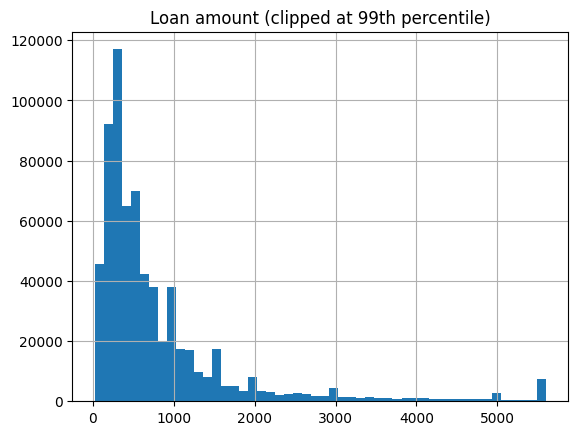

In [6]:
# Obs 1: loan amount distribution
print(clean['loan_amount'].describe())
clean['loan_amount'].clip(upper=clean['loan_amount'].quantile(0.99)).hist(bins=50)
plt.title('Loan amount (clipped at 99th percentile)'); plt.show()

**Observation 1:** *The dataset has 671,205 loans. The median loan is 500 and 75% of loans are 1,000 or less, but the largest is 100,000 and the mean (842) is above the median. The distribution is heavily right-skewed, with a few very large loans.

Share fully funded: 0.928
Share funded below 90%: 0.07


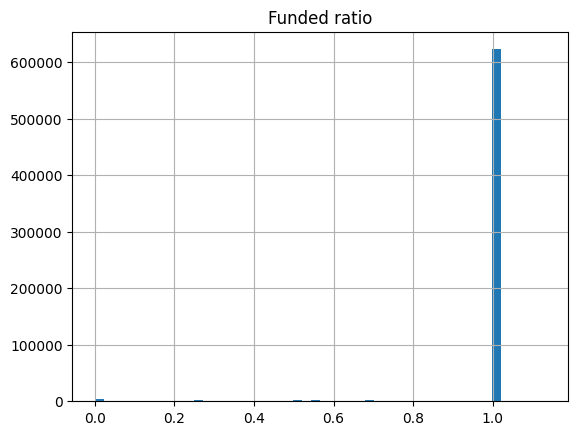

In [7]:
# Obs 2: how many loans are fully funded?
print('Share fully funded:', (clean['funded_ratio'] >= 1).mean().round(3))
print('Share funded below 90%:', (clean['funded_ratio'] < 0.9).mean().round(3))
clean['funded_ratio'].hist(bins=50); plt.title('Funded ratio'); plt.show()

**Observation 2:** *92.8% of loans are fully funded (funded ratio of 1 or more), and only 7% are funded below 90% of the loan amount. The funded ratio is concentrated at 1.0, so the under-funded loans are rare. That makes them natural candidates for the model to flag as potentially misallocated.

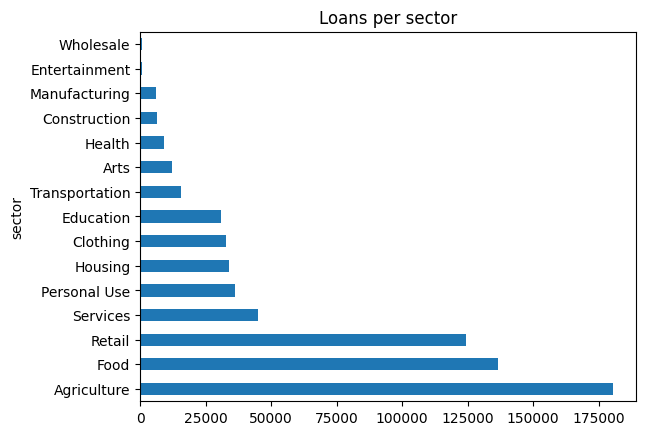

In [8]:
# Obs 3: sector mix
clean['sector'].value_counts().plot(kind='barh'); plt.title('Loans per sector'); plt.show()

**Observation 3:** *Three sectors dominate the data: Agriculture (about 180,000 loans), Food (about 136,000) and Retail (about 124,000). Sectors like Wholesale, Entertainment and Manufacturing have very few loans, so the data is heavily concentrated in a few sectors.

In [9]:
# Obs 4: relationship between loan size and number of lenders
print(clean[['loan_amount','lender_count','term_in_months','days_to_fund']].corr().round(2))

                loan_amount  lender_count  term_in_months  days_to_fund
loan_amount            1.00          0.80            0.18          0.12
lender_count           0.80          1.00            0.23          0.19
term_in_months         0.18          0.23            1.00          0.10
days_to_fund           0.12          0.19            0.10          1.00


**Observation 4:** **Loan amount and lender count are strongly correlated (0.80), which means larger loans normally attract more lenders. A large loan with very few lenders breaks this pattern, so it is a useful signal for the anomaly detector. Term (0.18) and days to fund (0.12) are only weakly related to loan amount.

## 5. Base model: Isolation Forest
Features are scaled first. The model returns -1 for anomalies and 1 for normal records.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

X = StandardScaler().fit_transform(clean[features])

iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42, n_jobs=-1)
clean['iso_flag'] = (iso.fit_predict(X) == -1).astype(int)
clean['anomaly_score'] = -iso.score_samples(X)   # higher = more anomalous
print('Flagged loans:', clean['iso_flag'].sum(), f"({clean['iso_flag'].mean():.1%})")

Flagged loans: 33561 (5.0%)


## 6. Validating the base model
There are no true labels, so we check validity in three ways:
1. Tune `contamination` and see how results change.
2. Compare flags against a simple rule-based flag (funded below 90% of the loan amount).
3. Inspect flagged loans by hand.

*Note: agreement with the rule is a sanity check, not an accuracy score, because `funded_ratio` is also a model input.*

In [11]:
from sklearn.metrics import precision_score, recall_score

clean['rule_flag'] = (clean['funded_ratio'] < 0.9).astype(int)

rows = []
for c in [0.01, 0.03, 0.05, 0.10]:
    m = IsolationForest(n_estimators=100, contamination=c, random_state=42, n_jobs=-1)
    f = (m.fit_predict(X) == -1).astype(int)
    rows.append({'contamination': c, 'flagged': f.sum(),
                 'precision_vs_rule': precision_score(clean['rule_flag'], f),
                 'recall_vs_rule': recall_score(clean['rule_flag'], f)})
pd.DataFrame(rows).round(3)

,contamination,flagged,precision_vs_rule,recall_vs_rule
0,0.01,6713,0.311,0.045
1,0.03,20137,0.349,0.150
2,0.05,33561,0.399,0.286
3,0.10,67121,0.425,0.610


In [12]:
# Inspect the most anomalous loans
clean.sort_values('anomaly_score', ascending=False)[
    ['id','sector','activity','country','loan_amount','funded_amount','funded_ratio',
     'lender_count','term_in_months','anomaly_score']].head(10)

,id,sector,activity,country,loan_amount,funded_amount,funded_ratio,lender_count,term_in_months,anomaly_score
148110,798219,Agriculture,Agriculture,Mexico,41700.0,41700.0,1.0,864,118.0,0.819064
126839,777718,Agriculture,Agriculture,Mexico,50000.0,50000.0,1.0,586,144.0,0.819064
125728,777202,Agriculture,Agriculture,Mexico,27000.0,27000.0,1.0,755,144.0,0.815194
84507,1082104,Agriculture,Agriculture,United States,10000.0,10000.0,1.0,390,42.0,0.814092
53409,1081287,Agriculture,Agriculture,United States,10000.0,10000.0,1.0,339,42.0,0.809150
128179,1084102,Agriculture,Agriculture,United States,10000.0,10000.0,1.0,322,42.0,0.809150
53255,1081288,Agriculture,Agriculture,United States,10000.0,10000.0,1.0,433,42.0,0.809150
153176,1086033,Agriculture,Agriculture,United States,10000.0,10000.0,1.0,407,39.0,0.807509
154410,1086079,Agriculture,Agriculture,United States,10000.0,10000.0,1.0,298,42.0,0.807509
57566,1081383,Agriculture,Agriculture,United States,10000.0,10000.0,1.0,246,42.0,0.807509


## 7. Further validation (planned for the final stage)
To check the base model, we will build other models that follow the same process (same cleaned features, same scaling) and compare their results with Isolation Forest:
- **Local Outlier Factor (LOF)**: density-based anomaly detection.
- **K-means (elbow method)**: loans far from their cluster centre are treated as anomalies.
- **Use vs sector/activity mismatch**: text-based check for loans whose stated `use` does not match their declared `sector`.

Comparison criteria: overlap between flagged sets, agreement with the rule-based flag, and manual review of flagged loans.

In [13]:
# Quick preview of the comparison (sampled, since LOF is slow on 600k+ rows)
from sklearn.neighbors import LocalOutlierFactor
samp = clean.sample(20000, random_state=42)
Xs = StandardScaler().fit_transform(samp[features])
lof_flag = (LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit_predict(Xs) == -1).astype(int)
iso_s = (IsolationForest(contamination=0.05, random_state=42).fit_predict(Xs) == -1).astype(int)
print('Overlap of LOF and Isolation Forest flags:', ((lof_flag == 1) & (iso_s == 1)).sum(), 'of', iso_s.sum())

Overlap of LOF and Isolation Forest flags: 170 of 1000
